# Twitch por dentro: análisis de redes con SageMath

## Proyecto MATI — versión ampliada y revisada

**Pregunta guía:** ¿cómo se organiza la red de usuarios de Twitch que tienen `language = PT`? ¿La popularidad está concentrada en unos pocos usuarios? ¿Qué usuarios conectan partes distintas de la red? ¿Existen comunidades? ¿Qué relación tiene la estructura con los atributos disponibles?

Este cuaderno analiza el **subgrafo inducido** por los usuarios cuya etiqueta de idioma es `PT`: se conservan esos vértices y únicamente las aristas cuyos dos extremos pertenecen a ese conjunto.

> **Importante sobre la interpretación:** `PT` identifica la etiqueta de idioma del dataset, no demuestra nacionalidad ni residencia portuguesa. Además, las aristas del dataset representan relaciones de seguimiento mutuo; por eso usamos un grafo no dirigido y hablamos de *relaciones mutuas*, no de amistades en sentido personal.

### Qué añade esta versión

1. Validaciones de los datos y comprobaciones matemáticas.
2. Distribución de grados con mediana correcta, percentiles y curva complementaria.
3. Comparación más justa con modelos aleatorios mediante varias réplicas.
4. Análisis de componentes y estimación reproducible de distancias.
5. Centralidades de grado, intermediación, cercanía y vector propio.
6. Comunidades en la componente principal, no solo en los 200 vértices de mayor grado.
7. Análisis de atributos y asociación entre idioma, popularidad y características de cuenta cuando estén disponibles.
8. Exportación de tablas y resultados para la memoria.
9. Un ejemplo pequeño y didáctico del algoritmo de Girvan–Newman.

### Cómo ejecutarlo

- Abre el cuaderno con **SageMath/Jupyter**.
- Coloca la carpeta `twitch_gamers/` junto al notebook. Debe contener `large_twitch_features.csv` y `large_twitch_edges.csv`.
- Ejecuta las celdas en orden.
- La primera ejecución puede tardar en las centralidades, comunidades y simulaciones aleatorias.
- Las celdas guardan resultados en `datos/`.

**No se incluyen resultados numéricos precalculados:** se obtendrán al ejecutar el notebook con los CSV originales. Así evitamos presentar como verificados valores que todavía no se han calculado en esta ejecución.


## 0. Preparación e importación de datos

Primero comprobamos que existen los archivos y leemos las características de los usuarios. Guardamos tanto el diccionario de atributos como el conjunto de identificadores `PT`.

In [1]:
import csv
import os
import math
import statistics
from pathlib import Path
from collections import Counter, defaultdict

import networkx as nx

set_random_seed(2026)

CARPETA_ORIGINAL = Path("twitch_gamers")
ARCHIVO_USUARIOS = CARPETA_ORIGINAL / "large_twitch_features.csv"
ARCHIVO_RELACIONES = CARPETA_ORIGINAL / "large_twitch_edges.csv"
CARPETA_DATOS = Path("datos")
CARPETA_DATOS.mkdir(exist_ok=True)

if not ARCHIVO_USUARIOS.exists() or not ARCHIVO_RELACIONES.exists():
    raise FileNotFoundError(
        "No se encuentran los CSV. Coloca la carpeta 'twitch_gamers' "
        "junto al notebook."
    )

# Leemos todos los atributos; conservamos los valores originales como texto.
atributos = {}
usuarios_por_idioma = defaultdict(list)
with ARCHIVO_USUARIOS.open(newline="", encoding="utf-8-sig") as f:
    lector = csv.DictReader(f)
    columnas_atributos = lector.fieldnames
    for fila in lector:
        u = int(fila["numeric_id"])
        atributos[u] = fila
        idioma = (fila.get("language") or "").strip().upper()
        usuarios_por_idioma[idioma].append(u)

usuarios_pt = set(usuarios_por_idioma["PT"])

print("Número de usuarios en el fichero:", len(atributos))
print("Número de etiquetas de idioma:", len(usuarios_por_idioma))
print("Usuarios con language = PT:", len(usuarios_pt))
print("Columnas disponibles:", columnas_atributos)

Número de usuarios en el fichero: 168114
Número de etiquetas de idioma: 21
Usuarios con language = PT: 2536
Columnas disponibles: ['views', 'mature', 'life_time', 'created_at', 'updated_at', 'numeric_id', 'dead_account', 'language', 'affiliate']


## 1. Construcción del grafo PT y validación

Leemos las relaciones y conservamos solo las que unen dos usuarios `PT`. Antes de construir el grafo eliminamos duplicados y lazos, si los hubiera. Como la fuente describe relaciones mutuas, el grafo es no dirigido.

**Alcance de las medidas:** el grado de un usuario en este grafo cuenta sus relaciones con otros usuarios `PT`, no todas sus relaciones en Twitch.

In [4]:
aristas_pt_set = set()
aristas_originales = 0
lazos_descartados = 0

with ARCHIVO_RELACIONES.open(newline="", encoding="utf-8-sig") as f:
    for fila in csv.DictReader(f):
        aristas_originales += 1
        u = int(fila["numeric_id_1"])
        v = int(fila["numeric_id_2"])
        if u in usuarios_pt and v in usuarios_pt:
            if u == v:
                lazos_descartados += 1
            else:
                aristas_pt_set.add(tuple(sorted((u, v))))

aristas_pt = sorted(aristas_pt_set)

G = Graph()
G.add_vertices(sorted(usuarios_pt))
G.add_edges(aristas_pt)

n, m = int(G.order()), int(G.size())
grados = [int(G.degree(v)) for v in G.vertices()]
suma_grados = sum(grados)
densidad = (2*m)/(n*(n-1)) if n > 1 else 0
aislados = sum(d == 0 for d in grados)

# Exportación del conjunto exacto utilizado.
CSV_PT_NODOS = CARPETA_DATOS / "twitch_PT_nodes.csv"
CSV_PT_ARISTAS = CARPETA_DATOS / "twitch_PT_edges.csv"
with CSV_PT_NODOS.open("w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["numeric_id", "language"])
    w.writerows((u, "PT") for u in sorted(usuarios_pt))
with CSV_PT_ARISTAS.open("w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["numeric_id_1", "numeric_id_2"])
    w.writerows(aristas_pt)

print(f"Vértices: {n:,}")
print(f"Aristas PT—PT únicas: {m:,}")
print(f"Grado medio: {float(sum(grados)/n):.3f}")
print(f"Densidad: {float(densidad):.6f} ({float(100*densidad):.3f}%)")
print(f"Aislados: {aislados}")
print(f"Lazos descartados: {lazos_descartados}")
print("¿Apretón de manos? Σ grados = 2m:", suma_grados == 2*m)
print("¿Tiene lazos?", G.has_loops())
print("¿Tiene aristas múltiples?", G.has_multiple_edges())
assert suma_grados == 2*m
assert not G.has_loops()
assert not G.has_multiple_edges()

Vértices: 2,536
Aristas PT—PT únicas: 42,952
Grado medio: 33.874
Densidad: 0.013362 (1.336%)
Aislados: 90
Lazos descartados: 0
¿Apretón de manos? Σ grados = 2m: True
¿Tiene lazos? False
¿Tiene aristas múltiples? False


## 2. Descripción general: grados y componentes

El **grado** es el número de relaciones mutuas PT de un vértice. La media puede verse muy afectada por los usuarios de grado muy alto, así que también calculamos mediana, cuartiles y percentiles.

La **densidad** compara las aristas observadas con todas las posibles. Los componentes conexos son conjuntos de vértices que pueden alcanzarse entre sí mediante caminos.

In [5]:
def percentil_ordenado(valores, p):
    """Percentil por interpolación lineal; p entre 0 y 100."""
    xs = sorted(valores)
    if not xs:
        return None
    pos = (len(xs)-1)*p/100
    lo, hi = int(math.floor(pos)), int(math.ceil(pos))
    if lo == hi:
        return xs[lo]
    return xs[lo] + (pos-lo)*(xs[hi]-xs[lo])

componentes = G.connected_components()
componentes_ordenados = sorted(componentes, key=len, reverse=True)
G_gigante = G.subgraph(componentes_ordenados[0]) if componentes_ordenados else Graph()
fraccion_gigante = G_gigante.order()/n if n else 0

resumen_general = [
    ("Vértices", n),
    ("Aristas", m),
    ("Grado medio", round(statistics.mean(grados), 3)),
    ("Grado mediano", statistics.median(grados)),
    ("Grado mínimo", min(grados) if grados else 0),
    ("Grado máximo", max(grados) if grados else 0),
    ("Percentil 25 del grado", percentil_ordenado(grados, 25)),
    ("Percentil 75 del grado", percentil_ordenado(grados, 75)),
    ("Densidad (%)", round(100*densidad, 4)),
    ("Aislados", aislados),
    ("Número de componentes", len(componentes_ordenados)),
    ("Componente mayor", G_gigante.order()),
    ("Porcentaje en componente mayor", round(100*fraccion_gigante, 2)),
]
for nombre, valor in resumen_general:
    print(f"{nombre:38s}: {valor}")

Vértices                              : 2536
Aristas                               : 42952
Grado medio                           : 33.874
Grado mediano                         : 17.0
Grado mínimo                          : 0
Grado máximo                          : 880
Percentil 25 del grado                : 6
Percentil 75 del grado                : 37
Densidad (%)                          : 1.3362
Aislados                              : 90
Número de componentes                 : 93
Componente mayor                      : 2442
Porcentaje en componente mayor        : 96.29


### 2.1 Visualización de una muestra

Dibujar miles de vértices simultáneamente suele ocultar la estructura. Esta figura muestra una muestra aleatoria reproducible de hasta 150 usuarios y las aristas que existen entre ellos. No representa toda la red.

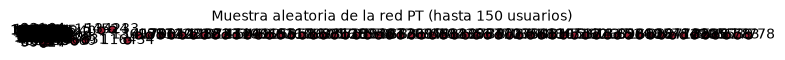

In [6]:
set_random_seed(2026)
muestra_ids = sample(list(G.vertices()), min(150, n))
G_muestra = G.subgraph(muestra_ids)
G_muestra.plot(
    vertex_size=25, vertex_color="#9D2235",
    edge_color="#BDA9A3", layout="spring",
    title="Muestra aleatoria de la red PT (hasta 150 usuarios)"
).show(figsize=8)

## 3. Distribución de grados: ¿hay hubs?

Un *hub* es un vértice con muchas conexiones respecto al resto. Un histograma o una escala logarítmica ayudan a visualizar desigualdad, pero **una recta aproximada en escala log-log no demuestra una ley potencial**.

Incluimos:
- histograma de frecuencias de grado;
- distribución complementaria `P(K ≥ k)`;
- coeficiente de variación, que resume la dispersión relativa.

El ajuste potencial de mínimos cuadrados se conserva únicamente como exploración visual, no como prueba estadística.

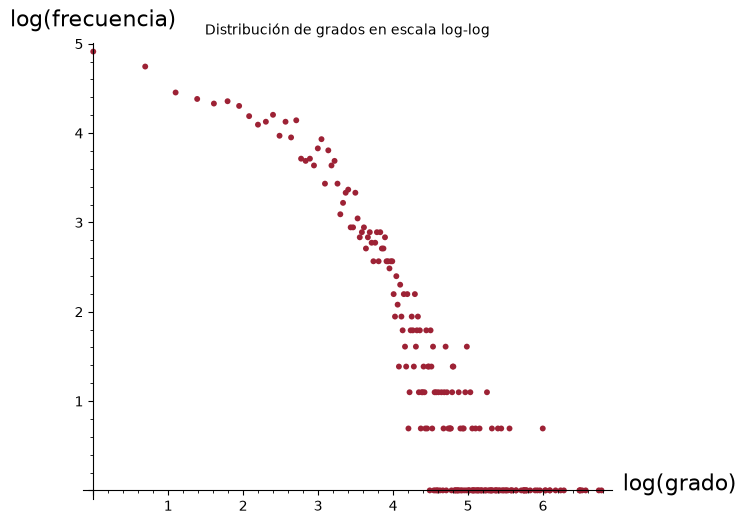

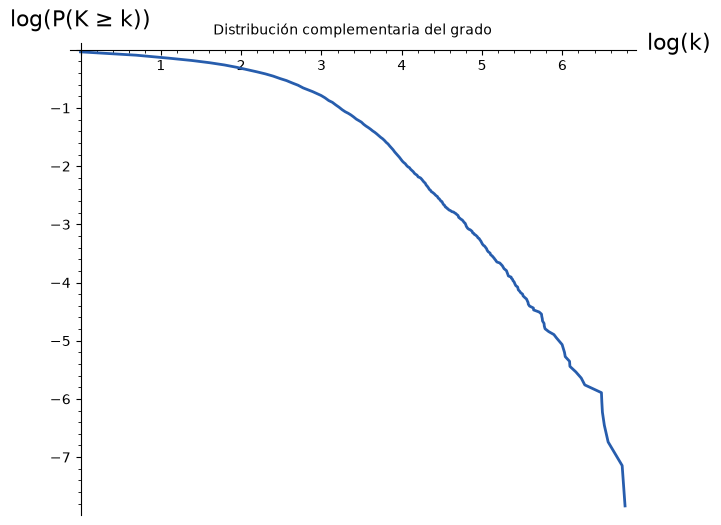

Coeficiente de variación del grado: 1.838
Grados más frecuentes: [(1, 136), (2, 115), (0, 90), (3, 86), (4, 80), (6, 78), (5, 76), (7, 74), (11, 67), (8, 66)]
Nota: estos gráficos describen la distribución; no prueban que sea escala libre.


In [7]:
frecuencias_grado = Counter(grados)
datos_grado = sorted((k, frecuencias_grado[k]) for k in frecuencias_grado)

# Histograma en escala log-log: omitimos grado 0 porque log(0) no existe.
puntos_log = [(k, f) for k, f in datos_grado if k > 0 and f > 0]
list_plot(
    [(math.log(k), math.log(f)) for k, f in puntos_log],
    plotjoined=False, color="#9D2235", size=18
).show(axes_labels=("log(grado)", "log(frecuencia)"),
       title="Distribución de grados en escala log-log", figsize=7)

# Distribución complementaria: proporción de vértices con grado >= k.
cola = []
for k in sorted(set(grados)):
    if k > 0:
        cola.append((k, sum(d >= k for d in grados)/n))
list_plot(
    [(math.log(k), math.log(p)) for k, p in cola if p > 0],
    plotjoined=True, color="#275DAD", thickness=2
).show(axes_labels=("log(k)", "log(P(K ≥ k))"),
       title="Distribución complementaria del grado", figsize=7)

media_grado = statistics.mean(grados)
desv_grado = math.sqrt(sum((d-media_grado)**2 for d in grados)/n)
cv_grado = desv_grado/media_grado if media_grado else 0
print("Coeficiente de variación del grado:", round(cv_grado, 3))
print("Grados más frecuentes:", frecuencias_grado.most_common(10))
print("Nota: estos gráficos describen la distribución; no prueban que sea escala libre.")

### 3.1 Ajuste exploratorio de modelos (opcional)

Se ajustan exponencial y potencial a las frecuencias observadas mediante mínimos cuadrados sobre la escala original. El error depende de la escala y de los puntos incluidos; no debe usarse para afirmar que una distribución es una ley potencial. Para una conclusión formal habría que estimar `xmin` por máxima verosimilitud, evaluar bondad de ajuste y comparar alternativas siguiendo Clauset, Shalizi y Newman (2009).

In [8]:
# Si el ajuste numérico de Sage no converge en alguna instalación,
# esta sección puede omitirse sin afectar al resto del análisis.
try:
    var("x a b")
    modelo_exp(x) = a*exp(b*x)
    modelo_pot(x) = a*x^b
    datos_ajuste = [(k, f) for k, f in datos_grado if k > 0 and f > 0]
    ajuste_exp = find_fit(datos_ajuste, modelo_exp,
                          initial_guess=[max(f for k,f in datos_ajuste), -0.05],
                          solution_dict=True)
    ajuste_pot = find_fit(datos_ajuste, modelo_pot,
                          initial_guess=[max(f for k,f in datos_ajuste), -1.0],
                          solution_dict=True)
    def error_ajuste(modelo, pars):
        return float(sum((f-float(modelo(k).subs(pars)))**2
                         for k,f in datos_ajuste))
    print("Error cuadrático exponencial:", error_ajuste(modelo_exp, ajuste_exp))
    print("Error cuadrático potencial:", error_ajuste(modelo_pot, ajuste_pot))
    print("Parámetros exponencial:", ajuste_exp)
    print("Parámetros potencial:", ajuste_pot)
except Exception as e:
    print("No se pudo completar el ajuste exploratorio:", repr(e))

Error cuadrático exponencial: 3469.860645561688
Error cuadrático potencial: 14984.011546112692
Parámetros exponencial: {a: 108.493800755632, b: -0.04742515296374618}
Parámetros potencial: {a: 175.8997210968065, b: -0.628961615957843}


## 4. Modelos de referencia: ¿qué estructura esperaríamos al azar?

Comparamos la red observada con cuatro modelos:
- **GNM:** Erdős–Rényi con el mismo número de vértices y exactamente `m` aristas.
- **GNP:** cada arista posible aparece con probabilidad `p` para igualar la densidad esperada.
- **Barabási–Albert (BA):** crecimiento con conexión preferencial.
- **Holme–Kim (HK):** conexión preferencial y cierre de triángulos.

Una sola simulación puede ser atípica. Por eso repetimos GNM, GNP, BA y HK varias veces y resumimos media y desviación típica. BA y HK no garantizan exactamente `m` aristas; imprimimos el número real.

In [9]:
p = densidad
# Parámetro m0 de BA/HK: número aproximado de enlaces nuevos por vértice.
m_modelo = max(1, min(10, int(round(m/n))))

def crear_modelos(seed):
    set_random_seed(seed)
    return {
        "GNM": graphs.RandomGNM(n, m),
        "GNP": graphs.RandomGNP(n, p),
        "BA": graphs.RandomBarabasiAlbert(n, m_modelo),
        "HK": graphs.RandomHolmeKim(n, m_modelo, 0.5)
    }

def metricas_modelo(H):
    return {
        "vertices": int(H.order()),
        "aristas": int(H.size()),
        "grado_medio": float(H.average_degree()),
        "clustering": float(H.clustering_average()),
        "componentes": len(H.connected_components())
    }

modelos_una_replica = crear_modelos(2026)
for nombre, H in modelos_una_replica.items():
    print(nombre, metricas_modelo(H))

GNM {'vertices': 2536, 'aristas': 42952, 'grado_medio': 33.873817034700316, 'clustering': 0.013396423955156824, 'componentes': 1}
GNP {'vertices': 2536, 'aristas': 43107, 'grado_medio': 33.996056782334385, 'clustering': 0.013602489772524371, 'componentes': 1}
BA {'vertices': 2536, 'aristas': 25260, 'grado_medio': 19.9211356466877, 'clustering': 0.03161402256987515, 'componentes': 1}
HK {'vertices': 2536, 'aristas': 25186, 'grado_medio': 19.86277602523659, 'clustering': 0.12253234033656149, 'componentes': 1}


In [10]:
# Réplicas: aumenta N_REPLICAS si el tiempo de ejecución lo permite.
N_REPLICAS = 20
resultados_modelos = defaultdict(list)

for r in range(N_REPLICAS):
    modelos_r = crear_modelos(3000 + r)
    for nombre, H in modelos_r.items():
        resultados_modelos[nombre].append(metricas_modelo(H))

print(f"Resumen de {N_REPLICAS} réplicas")
for nombre, filas in resultados_modelos.items():
    print("\\n", nombre)
    for metrica in ["aristas", "grado_medio", "clustering", "componentes"]:
        valores = [fila[metrica] for fila in filas]
        print(f"  {metrica:15s}: media={statistics.mean(valores):.4f}, "
              f"desv={statistics.pstdev(valores):.4f}")

Resumen de 20 réplicas
\n GNM
  aristas        : media=42952.0000, desv=0.0000
  grado_medio    : media=33.8738, desv=0.0000
  clustering     : media=0.0133, desv=0.0001
  componentes    : media=1.0000, desv=0.0000
\n GNP
  aristas        : media=42961.7000, desv=211.5235
  grado_medio    : media=33.8815, desv=0.1668
  clustering     : media=0.0134, desv=0.0002
  componentes    : media=1.0000, desv=0.0000
\n BA
  aristas        : media=25260.0000, desv=0.0000
  grado_medio    : media=19.9211, desv=0.0000
  clustering     : media=0.0311, desv=0.0010
  componentes    : media=1.0000, desv=0.0000
\n HK
  aristas        : media=25183.5000, desv=8.1456
  grado_medio    : media=19.8608, desv=0.0064
  clustering     : media=0.1245, desv=0.0020
  componentes    : media=1.0000, desv=0.0000


### 4.1 Comparación visual de clustering

El clustering medio de la red real se compara con la distribución obtenida en las réplicas. Si el valor real queda muy por encima de los modelos aleatorios, hay más cierre local de triángulos del que explicaría la densidad por sí sola. Esto no identifica por sí mismo la causa.

In [11]:
clustering_real = float(G.clustering_average())
print("Clustering medio Twitch PT:", round(clustering_real, 5))
for nombre, filas in resultados_modelos.items():
    vals = [f["clustering"] for f in filas]
    print(f"{nombre:5s}: media {statistics.mean(vals):.5f}; "
          f"desv. {statistics.pstdev(vals):.5f}; "
          f"mín. {min(vals):.5f}; máx. {max(vals):.5f}")

Clustering medio Twitch PT: 0.30307
GNM  : media 0.01331; desv. 0.00013; mín. 0.01300; máx. 0.01357
GNP  : media 0.01338; desv. 0.00021; mín. 0.01299; máx. 0.01370
BA   : media 0.03108; desv. 0.00100; mín. 0.02924; máx. 0.03285
HK   : media 0.12448; desv. 0.00202; mín. 0.12081; máx. 0.12766


## 5. Componentes y distancias: ¿es una red de mundo pequeño?

La distancia entre dos vértices es la longitud del camino más corto. En un grafo desconectado no existe camino entre todos los pares, así que calculamos distancias en la **componente conexa mayor**.

Para reducir el coste, estimamos la distancia media tomando una muestra de orígenes y ejecutando BFS desde cada uno. La semilla hace que la muestra sea reproducible. Informamos de cuántos orígenes se han utilizado.

In [12]:
def bfs_distancias(H, origen):
    dist = {origen: 0}
    cola = [origen]
    i = 0
    while i < len(cola):
        u = cola[i]; i += 1
        for v in H.neighbors(u):
            if v not in dist:
                dist[v] = dist[u] + 1
                cola.append(v)
    return dist

def estimar_distancia_media(H, n_origenes=200, seed=2026):
    if H.order() <= 1:
        return {"distancia_media_estimada": 0.0, "origenes": 0}
    set_random_seed(seed)
    vertices = list(H.vertices())
    origenes = sample(vertices, min(n_origenes, len(vertices)))
    suma = 0
    cuenta = 0
    for u in origenes:
        dist = bfs_distancias(H, u)
        suma += sum(d for v,d in dist.items() if v != u)
        cuenta += len(dist)-1
    return {
        "distancia_media_estimada": suma/cuenta if cuenta else 0.0,
        "origenes": len(origenes)
    }

print("Componentes:", len(componentes_ordenados))
print("Tamaño de las 10 mayores:", [len(c) for c in componentes_ordenados[:10]])
print("Componente mayor:", G_gigante.order(), f"({100*fraccion_gigante:.2f}% de los vértices)")
print("Diámetro de la componente mayor:", G_gigante.diameter())
print("Distancia media estimada:", estimar_distancia_media(G_gigante, 200, 2026))

Componentes: 93
Tamaño de las 10 mayores: [2442, 2, 2, 1, 1, 1, 1, 1, 1, 1]
Componente mayor: 2442 (96.29% de los vértices)
Diámetro de la componente mayor: 7
Distancia media estimada: {'distancia_media_estimada': 642269/244100, 'origenes': 200}


### 5.1 Criterio de mundo pequeño

No basta con que la distancia media sea pequeña. La idea de mundo pequeño combina:
1. distancias medias relativamente cortas;
2. clustering notablemente superior al de una red aleatoria comparable.

Usamos GNP como referencia de clustering y distancia, y presentamos los resultados como evidencia comparativa, no como una etiqueta automática.

In [13]:
G_gnp_ref = modelos_una_replica["GNP"]
G_gnp_gigante = G_gnp_ref.subgraph(max(G_gnp_ref.connected_components(), key=len))
dist_real = estimar_distancia_media(G_gigante, 200, 2026)
dist_gnp = estimar_distancia_media(G_gnp_gigante, 200, 2027)

print("Clustering real:", float(G.clustering_average()))
print("Clustering GNP:", float(G_gnp_ref.clustering_average()))
print("Distancia media estimada real:", dist_real)
print("Distancia media estimada GNP:", dist_gnp)
print("Interpretación: valorar conjuntamente clustering y distancias.")

Clustering real: 0.3030694492168472
Clustering GNP: 0.013602489772524371
Distancia media estimada real: {'distancia_media_estimada': 642269/244100, 'origenes': 200}
Distancia media estimada GNP: {'distancia_media_estimada': 661883/253500, 'origenes': 200}
Interpretación: valorar conjuntamente clustering y distancias.


## 6. Centralidad: ¿quién es importante y por qué?

Calculamos cuatro medidas:
- **Grado:** número de vecinos directos.
- **Intermediación (betweenness):** frecuencia con la que un vértice aparece en caminos mínimos entre otros.
- **Cercanía (closeness):** inversa de la distancia media a los demás vértices alcanzables.
- **Vector propio (eigenvector):** da más peso a conexiones con vértices que también son importantes.

Para comparar centralidades usamos la componente mayor, evitando mezclar vértices aislados o componentes distintas en medidas basadas en distancias. Los IDs son identificadores del dataset, no nombres de canales.

In [15]:
# Todas las medidas de distancia se calculan sobre la componente gigante.
centralidad_grado = {v: int(G_gigante.degree(v)) for v in G_gigante.vertices()}
centralidad_intermediacion = G_gigante.centrality_betweenness(normalized=True)
centralidad_cercania = G_gigante.centrality_closeness()

try:
    centralidad_vector = G_gigante.eigenvector_centrality()
except Exception as e:
    centralidad_vector = {}
    print("No se pudo calcular eigenvector centrality:", repr(e))

def top_diccionario(dic, k=10):
    return sorted(dic.items(), key=lambda par: par[1], reverse=True)[:k]

for nombre, dic in [
    ("Grado", centralidad_grado),
    ("Intermediación", centralidad_intermediacion),
    ("Cercanía", centralidad_cercania),
    ("Vector propio", centralidad_vector)
]:
    print("\\nTOP", nombre)
    for v, valor in top_diccionario(dic, 10):
        print(v, round(float(valor), 6))

No se pudo calcular eigenvector centrality: AttributeError("'Graph' object has no attribute 'eigenvector_centrality'")
\nTOP Grado
122266 880.0
161540 849.0
55969 713.0
128589 680.0
160961 664.0
50779 659.0
8094 656.0
124315 533.0
32972 510.0
81837 477.0
\nTOP Intermediación
161540 0.088873
122266 0.076248
55969 0.059285
160961 0.056108
128589 0.041853
50779 0.032817
8094 0.02925
32972 0.027171
124315 0.018545
102521 0.01806
\nTOP Cercanía
122266 0.580637
161540 0.568468
55969 0.555278
50779 0.545841
128589 0.544744
160961 0.544744
8094 0.541362
32972 0.525398
124315 0.522251
81837 0.517161
\nTOP Vector propio


### 6.1 ¿Coinciden las distintas nociones de importancia?

Un usuario puede tener muchos vecinos sin ser un puente entre grupos. Otro puede tener menos vecinos, pero ocupar una posición estratégica entre zonas de la red. Comparamos los conjuntos de los diez primeros puestos.

In [16]:
tops = {
    "grado": {v for v,x in top_diccionario(centralidad_grado, 10)},
    "intermediacion": {v for v,x in top_diccionario(centralidad_intermediacion, 10)},
    "cercania": {v for v,x in top_diccionario(centralidad_cercania, 10)},
    "vector_propio": {v for v,x in top_diccionario(centralidad_vector, 10)}
}
for a in tops:
    for b in tops:
        if a < b:
            print(f"Coincidencia {a} / {b}: {len(tops[a] & tops[b])} usuarios",
                  sorted(tops[a] & tops[b]))

Coincidencia grado / intermediacion: 9 usuarios [8094, 32972, 50779, 55969, 122266, 124315, 128589, 160961, 161540]
Coincidencia grado / vector_propio: 0 usuarios []
Coincidencia intermediacion / vector_propio: 0 usuarios []
Coincidencia cercania / grado: 10 usuarios [8094, 32972, 50779, 55969, 81837, 122266, 124315, 128589, 160961, 161540]
Coincidencia cercania / intermediacion: 9 usuarios [8094, 32972, 50779, 55969, 122266, 124315, 128589, 160961, 161540]
Coincidencia cercania / vector_propio: 0 usuarios []


### 6.2 Visualizar el entorno de un usuario con alto grado

Representamos un vértice con grado alto y sus vecinos directos. Es una visualización local: no debe confundirse con la red completa ni con una comunidad detectada.

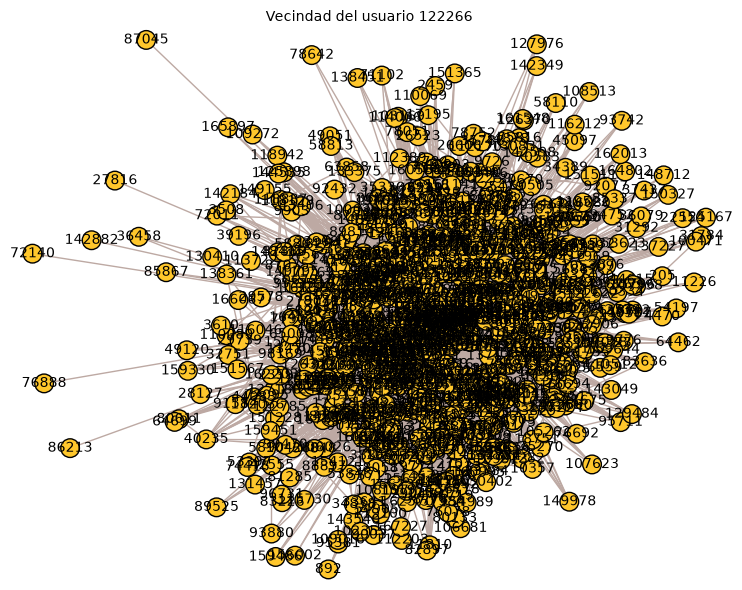

In [17]:
lider = top_diccionario(centralidad_grado, 1)[0][0]
vecinos_lider = G_gigante.neighbors(lider)
H_vecindad = G_gigante.subgraph([lider] + vecinos_lider)
H_vecindad.plot(
    vertex_colors={"#9D2235": [lider], "#FFC72C": vecinos_lider},
    vertex_size=180, edge_color="#BDA9A3", layout="spring",
    title=f"Vecindad del usuario {lider}"
).show(figsize=8)

## 7. Triángulos, clustering, cliques y bipartición

Son conceptos relacionados, pero distintos:
- un **triángulo** es un conjunto de tres vértices conectados por sus tres aristas;
- el **clustering** mide la tendencia a cerrar triángulos alrededor de los vértices;
- un **clique** es un conjunto donde todos están conectados con todos;
- un grafo **bipartito** admite una división en dos conjuntos sin aristas internas.

El clique máximo puede ser costoso de calcular. Para mantener el tiempo razonable, lo buscamos en el subgrafo inducido por los 100 vértices de mayor grado de la componente gigante. El resultado es el clique máximo de ese subgrafo, no necesariamente el de toda la red.

In [18]:
print("¿Es bipartito?", G.is_bipartite())
print("Número de triángulos:", int(G.triangles_count()))
print("Clustering medio:", float(G.clustering_average()))
print("Transitivity (si está disponible en NetworkX):",
      nx.transitivity(G.networkx_graph()))

# Clique máximo en el subgrafo inducido por los 100 vértices de mayor grado.
vertices_top_clique = sorted(G_gigante.vertices(), key=lambda v: G_gigante.degree(v), reverse=True)[:min(100, G_gigante.order())]
G_top_clique = G_gigante.subgraph(vertices_top_clique)
try:
    clique_max = G_top_clique.clique_maximum()
    print("Tamaño del clique máximo entre los 100 vértices de mayor grado:", len(clique_max))
    print("Cota inferior para el número cromático del grafo completo:", len(clique_max))
except Exception as e:
    clique_max = []
    print("No se pudo calcular el clique máximo del subgrafo top-100:", repr(e))

¿Es bipartito? False
Número de triángulos: 262853
Clustering medio: 0.3030694492168472
Transitivity (si está disponible en NetworkX): 0.12460015586099929
Tamaño del clique máximo entre los 100 vértices de mayor grado: 17
Cota inferior para el número cromático del grafo completo: 17


## 8. Detección de comunidades en la componente gigante

Una comunidad es un grupo con más conexiones internas de las que esperaríamos respecto a una referencia de mezcla. Aplicamos **greedy modularity** a la componente gigante completa mediante NetworkX.

Esta heurística no garantiza encontrar la partición óptima. Informamos del número de comunidades, sus tamaños y la modularidad de la partición. No llamamos “núcleo” a la componente gigante: son conceptos distintos.

In [19]:
G_nx = G_gigante.networkx_graph()
comunidades = list(nx.algorithms.community.greedy_modularity_communities(G_nx))
tamanos_comunidades = sorted([len(c) for c in comunidades], reverse=True)
modularidad = nx.algorithms.community.modularity(G_nx, comunidades)

print("Número de comunidades:", len(comunidades))
print("Tamaños de las 15 mayores:", tamanos_comunidades[:15])
print("Modularidad:", round(modularidad, 5))

# Tabla de pertenencia usuario -> comunidad.
comunidad_por_usuario = {}
for i, comunidad in enumerate(comunidades):
    for u in comunidad:
        comunidad_por_usuario[u] = i

CSV_COMUNIDADES = CARPETA_DATOS / "comunidades_PT.csv"
with CSV_COMUNIDADES.open("w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["numeric_id", "community"])
    w.writerows((u, comunidad_por_usuario[u]) for u in sorted(comunidad_por_usuario))
print("Asignaciones guardadas en:", CSV_COMUNIDADES)

Número de comunidades: 15
Tamaños de las 15 mayores: [1150, 913, 271, 67, 9, 8, 5, 4, 3, 2, 2, 2, 2, 2, 2]
Modularidad: 0.25286
Asignaciones guardadas en: datos/comunidades_PT.csv


### 8.1 Visualización de comunidades (muestra)

Colorear toda la componente gigante puede resultar ilegible. Seleccionamos una muestra de vértices y coloreamos cada uno según su comunidad. Esta figura permite inspeccionar patrones, pero la detección se ha realizado sobre la componente gigante completa.

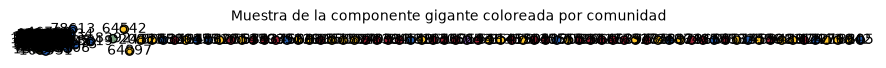

In [20]:
set_random_seed(2028)
muestra_comunidades = sample(list(G_gigante.vertices()),
                             min(250, G_gigante.order()))
H_comunidades = G_gigante.subgraph(muestra_comunidades)
colores = ["#9D2235", "#FFC72C", "#275DAD", "#7A9E7E",
           "#9467BD", "#E07A5F", "#6B7280", "#4C956C"]
colores_por_grupo = defaultdict(list)
for u in H_comunidades.vertices():
    grupo = comunidad_por_usuario.get(u, -1)
    colores_por_grupo[colores[grupo % len(colores)]].append(u)
H_comunidades.plot(
    vertex_colors=dict(colores_por_grupo),
    vertex_size=35, edge_color="#C9C9C9", layout="spring",
    title="Muestra de la componente gigante coloreada por comunidad"
).show(figsize=9)

## 9. Atributos: ¿qué más sabemos de los usuarios?

El dataset contiene características adicionales. Primero inspeccionamos los nombres de columnas reales; después seleccionamos automáticamente algunas variables numéricas si están disponibles.

La asociación entre grado y número de visualizaciones, antigüedad u otra característica **no implica causalidad**. Además, el grado de este análisis solo cuenta relaciones dentro del grupo PT.

In [21]:
print("Columnas disponibles en el fichero de características:")
for c in columnas_atributos:
    print("-", c)

# Convierte una columna a número cuando sea posible.
def valores_numericos(columna, ids):
    pares = []
    for u in ids:
        valor = atributos[u].get(columna, "")
        try:
            x = float(valor)
            if math.isfinite(x):
                pares.append((u, x))
        except (TypeError, ValueError):
            pass
    return pares

# Candidatas frecuentes en el dataset Twitch Gamers.
candidatas = ["views", "life_time", "created_at", "updated_at",
              "mature", "partner", "affiliate", "dead_account"]
columnas_numericas = {}
for col in candidatas:
    if col in columnas_atributos:
        pares = valores_numericos(col, usuarios_pt)
        if len(pares) >= 10 and len(set(x for u,x in pares)) > 1:
            columnas_numericas[col] = pares

print("\\nVariables numéricas utilizables:")
for col, pares in columnas_numericas.items():
    print(col, "—", len(pares), "usuarios con valor numérico")

Columnas disponibles en el fichero de características:
- views
- mature
- life_time
- created_at
- updated_at
- numeric_id
- dead_account
- language
- affiliate
\nVariables numéricas utilizables:
views — 2536 usuarios con valor numérico
life_time — 2536 usuarios con valor numérico
mature — 2536 usuarios con valor numérico
affiliate — 2536 usuarios con valor numérico
dead_account — 2536 usuarios con valor numérico


### 9.1 Correlación de Spearman con el grado

Spearman mide asociación monótona y es menos sensible que Pearson a escalas muy asimétricas. Calculamos los rangos con promedio en caso de empates y después la correlación de Pearson entre rangos.

In [23]:
def rangos_promedio(valores):
    valores = [float(v) for v in valores]

    orden = sorted(range(len(valores)), key=lambda i: valores[i])
    rangos = [0.0] * len(valores)

    i = 0
    while i < len(orden):
        j = i

        # Buscar valores empatados
        while j + 1 < len(orden) and valores[orden[j+1]] == valores[orden[i]]:
            j += 1

        # Asignar el rango medio a los valores empatados
        rango = (i + 1 + j + 1) / 2.0

        for k in range(i, j+1):
            rangos[orden[k]] = rango

        i = j + 1

    return rangos


def correlacion_pearson(x, y):
    # Convertir a números float de Python
    x = [float(a) for a in x]
    y = [float(b) for b in y]

    if len(x) != len(y) or len(x) < 3:
        return None

    mx = sum(x) / len(x)
    my = sum(y) / len(y)

    sx = math.sqrt(sum((a - mx)**2 for a in x))
    sy = math.sqrt(sum((b - my)**2 for b in y))

    if sx == 0 or sy == 0:
        return None

    return sum((a-mx)*(b-my) for a,b in zip(x,y)) / (sx*sy)


grados_por_id = {u: int(G.degree(u)) for u in G.vertices()}
correlaciones_spearman = {}

for col, pares in columnas_numericas.items():
    ids = [u for u, x in pares]

    x = [grados_por_id[u] for u in ids]
    y = [valor for u, valor in pares]

    rho = correlacion_pearson(
        rangos_promedio(x),
        rangos_promedio(y)
    )

    correlaciones_spearman[col] = (rho, len(ids))

    print(f"{col:15s}: rho={rho if rho is not None else 'no calculable'}; n={len(ids)}")

views          : rho=0.5994447366735831; n=2536
life_time      : rho=0.141161289879417; n=2536
mature         : rho=0.16965551175600643; n=2536
affiliate      : rho=0.1079512806029836; n=2536
dead_account   : rho=-0.20612650880182606; n=2536


### 9.2 Comparación de estructura entre idiomas

Para cada idioma construimos conceptualmente su subgrafo inducido: usuarios con esa etiqueta y relaciones internas. La tabla compara tamaño, aristas internas, densidad, grado medio, mediana y aislados. No comparamos solo densidades: el tamaño de cada grupo influye en esa medida.

In [26]:
print("Idioma | usuarios | aristas internas | densidad (%) | grado medio | mediana | máximo | aislados")

for fila in filas_idioma:
    idioma = str(fila[0])
    usuarios = int(fila[1])
    aristas = int(fila[2])
    densidad = float(fila[3]) * 100
    grado_medio = float(fila[4])
    mediana = float(fila[5])
    maximo = int(fila[6])
    aislados = int(fila[7])

    print(f"{idioma:8s} | {usuarios:7d} | {aristas:8d} | "
          f"{densidad:10.3f} | {grado_medio:10.2f} | {mediana:7.1f} | "
          f"{maximo:6d} | {aislados:7d}")

Idioma | usuarios | aristas internas | densidad (%) | grado medio | mediana | máximo | aislados
EN       |  124411 |  5484872 |      0.071 |      88.17 |    35.0 |  28073 |     264
DE       |    9428 |   160753 |      0.362 |      34.10 |    16.0 |   4247 |     184
FR       |    6799 |   123644 |      0.535 |      36.37 |    19.0 |   2081 |      75
ES       |    5699 |    85893 |      0.529 |      30.14 |    14.0 |   1131 |     161
RU       |    4821 |    46482 |      0.400 |      19.28 |     9.0 |   1504 |     144
ZH       |    2828 |    67858 |      1.698 |      47.99 |    23.0 |   1378 |      35
PT       |    2536 |    42952 |      1.336 |      33.87 |    17.0 |    880 |      90
OTHER    |    1429 |      202 |      0.020 |       0.28 |     0.0 |     17 |    1250
JA       |    1327 |     8384 |      0.953 |      12.64 |     6.0 |    397 |     105
IT       |    1230 |    15859 |      2.098 |      25.79 |    12.0 |    348 |      27
KO       |    1215 |    14775 |      2.003 |      24.3

## 10. Afinidad por idioma (assortatividad nominal)

La assortatividad por atributo indica si las aristas tienden a unir vértices con la misma etiqueta. Calculamos la fracción observada de aristas intralingüísticas y la comparamos con la fracción esperada al emparejar al azar los extremos de las aristas, conservando la proporción de extremos de cada idioma.

El coeficiente se interpreta aproximadamente así: valores positivos indican preferencia por conexiones entre etiquetas iguales; cero, mezcla compatible con esa referencia; valores negativos, más conexiones entre etiquetas distintas. No demuestra que el idioma cause las relaciones.

In [27]:
extremos_idioma = Counter()
aristas_mismo_idioma = 0
total_aristas = 0

with ARCHIVO_RELACIONES.open(newline="", encoding="utf-8-sig") as f:
    for fila in csv.DictReader(f):
        u = int(fila["numeric_id_1"]); v = int(fila["numeric_id_2"])
        lu = (atributos[u].get("language") or "").strip().upper()
        lv = (atributos[v].get("language") or "").strip().upper()
        if not lu or not lv:
            continue
        total_aristas += 1
        extremos_idioma[lu] += 1
        extremos_idioma[lv] += 1
        if lu == lv:
            aristas_mismo_idioma += 1

fraccion_observada = aristas_mismo_idioma/total_aristas if total_aristas else 0
fraccion_esperada = sum((c/(2*total_aristas))**2
                        for c in extremos_idioma.values()) if total_aristas else 0
assortatividad_idioma = (
    (fraccion_observada-fraccion_esperada)/(1-fraccion_esperada)
    if total_aristas and fraccion_esperada < 1 else None
)

print("Aristas consideradas:", total_aristas)
print("Fracción de aristas intralingüísticas observada:", round(fraccion_observada, 5))
print("Fracción esperada bajo mezcla aleatoria:", round(fraccion_esperada, 5))
print("Assortatividad por idioma:", assortatividad_idioma)

with (CARPETA_DATOS / "afinidad_idioma.csv").open("w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["measure","value"])
    w.writerows([
        ["all_edges", total_aristas],
        ["same_language_edges", aristas_mismo_idioma],
        ["observed_same_language_fraction", fraccion_observada],
        ["expected_random_mixing_fraction", fraccion_esperada],
        ["language_assortativity", assortatividad_idioma]
    ])

Aristas consideradas: 6797557
Fracción de aristas intralingüísticas observada: 0.89999
Fracción esperada bajo mezcla aleatoria: 0.73306
Assortatividad por idioma: 15427122308063/24669053615035


## 11. Demostración constructiva: Girvan–Newman en un grafo pequeño

El algoritmo de Girvan–Newman detecta comunidades eliminando repetidamente la arista con mayor intermediación. La intermediación de aristas mide cuántos caminos mínimos pasan por cada arista.

La demostración usa un grafo pequeño creado expresamente para que se pueda inspeccionar. No ejecutamos el algoritmo completo sobre la red Twitch, porque recalcular intermediación de aristas tras cada eliminación puede ser costoso.

Intermediación de aristas:
(3, 4) 16.0
(1, 3) 7.5
(2, 3) 7.5
(4, 5) 7.5
(4, 6) 7.5
(0, 1) 3.5
(0, 2) 3.5
(5, 7) 3.5
(6, 7) 3.5
(1, 2) 1.0
(5, 6) 1.0
Arista eliminada: (3, 4)
Componentes después de eliminarla: [4, 4]


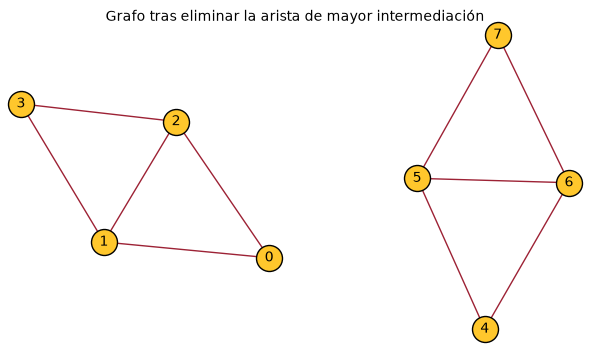

In [33]:
import networkx as nx

# Construir un grafo de NetworkX a partir del grafo de SageMath.
G_nx = nx.Graph()
G_nx.add_nodes_from(D.vertices())
G_nx.add_edges_from(D.edges(labels=False))

# Calcular la intermediación de las aristas.
inter_aristas = nx.edge_betweenness_centrality(
    G_nx,
    normalized=False
)

print("Intermediación de aristas:")
for arista, valor in sorted(
    inter_aristas.items(),
    key=lambda p: p[1],
    reverse=True
):
    print(arista, round(float(valor), 3))

# Una iteración: eliminar una arista de máxima intermediación.
maximo = max(inter_aristas.values())
aristas_maximas = [e for e, v in inter_aristas.items() if v == maximo]
arista_eliminar = aristas_maximas[0]

D2 = D.copy()
D2.delete_edge(*arista_eliminar)

print("Arista eliminada:", arista_eliminar)
print("Componentes después de eliminarla:",
      [len(c) for c in D2.connected_components()])

D2.plot(vertex_size=350, vertex_color="#FFC72C",
        edge_color="#9D2235", layout="spring",
        title="Grafo tras eliminar la arista de mayor intermediación").show(figsize=6)


## 12. Comprobación matemática manual: matriz de adyacencia y Havel–Hakimi

Seleccionamos seis vértices de grado alto en la componente gigante. La matriz de adyacencia del subgrafo inducido debe ser cuadrada, simétrica y tener diagonal cero.

El algoritmo de Havel–Hakimi comprueba si una secuencia de grados es gráfica. **No demuestra que una matriz de adyacencia concreta sea correcta**; para eso comparamos las sumas de filas con los grados del subgrafo.

In [34]:
seis = [v for v,d in top_diccionario(centralidad_grado, 6)]
H6 = G_gigante.subgraph(seis)
M = H6.adjacency_matrix()
secuencia = sorted([int(H6.degree(v)) for v in H6.vertices()], reverse=True)

print("IDs seleccionados:", seis)
show(M)
print("Matriz cuadrada:", M.nrows() == M.ncols())
print("Matriz simétrica:", M == M.transpose())
print("Diagonal cero:", all(M[i,i] == 0 for i in range(M.nrows())))
sumas_filas = [sum(M[i,j] for j in range(M.ncols())) for i in range(M.nrows())]
grados_subgrafo = [int(H6.degree(v)) for v in H6.vertices()]
print("Sumas de filas:", sumas_filas)
print("Grados en el subgrafo:", grados_subgrafo)
print("Coinciden (en el orden de vértices):", sumas_filas == grados_subgrafo)

def havel_hakimi(secuencia):
    pendientes = sorted([int(d) for d in secuencia], reverse=True)
    pasos = [pendientes[:]]
    while pendientes and pendientes[0] > 0:
        k = pendientes.pop(0)
        if k > len(pendientes):
            return pasos, False
        for i in range(k):
            pendientes[i] -= 1
            if pendientes[i] < 0:
                return pasos + [pendientes[:]], False
        pendientes = sorted(pendientes, reverse=True)
        pasos.append(pendientes[:])
    return pasos, True

pasos_hh, es_grafica = havel_hakimi(secuencia)
print("\\nSecuencia de grados:", secuencia)
for i, paso in enumerate(pasos_hh):
    print(i, ":", paso)
print("¿Es una secuencia gráfica?:", es_grafica)

IDs seleccionados: [122266, 161540, 55969, 128589, 160961, 50779]


[0 1 1 1 0 1]
[1 0 0 1 1 1]
[1 0 0 1 1 1]
[1 1 1 0 0 1]
[0 1 1 0 0 0]
[1 1 1 1 0 0]

Matriz cuadrada: True
Matriz simétrica: True
Diagonal cero: True
Sumas de filas: [4, 4, 4, 4, 2, 4]
Grados en el subgrafo: [4, 4, 4, 4, 2, 4]
Coinciden (en el orden de vértices): True
\nSecuencia de grados: [4, 4, 4, 4, 4, 2]
0 : [4, 4, 4, 4, 4, 2]
1 : [3, 3, 3, 3, 2]
2 : [2, 2, 2, 2]
3 : [2, 1, 1]
4 : [0, 0]
¿Es una secuencia gráfica?: True


## 13. Resumen automático y exportación

Esta sección reúne medidas principales. Los resultados se guardan en CSV para incorporarlos a tablas o gráficas de la memoria. La distancia se etiqueta como estimación porque se calcula a partir de una muestra de orígenes.

In [35]:
distancia_final = estimar_distancia_media(G_gigante, 200, 2026)
resumen = [
    ("usuarios_PT", n),
    ("aristas_PT_PT", m),
    ("grado_medio", statistics.mean(grados)),
    ("grado_mediano", statistics.median(grados)),
    ("grado_maximo", max(grados)),
    ("densidad", densidad),
    ("usuarios_aislados", aislados),
    ("numero_componentes", len(componentes_ordenados)),
    ("tamano_componente_mayor", G_gigante.order()),
    ("fraccion_componente_mayor", fraccion_gigante),
    ("clustering_medio", float(G.clustering_average())),
    ("triangulos", int(G.triangles_count())),
    ("modularidad_greedy", modularidad),
    ("numero_comunidades", len(comunidades)),
    ("distancia_media_estimada", distancia_final["distancia_media_estimada"]),
    ("origenes_BFS", distancia_final["origenes"]),
    ("assortatividad_idioma", assortatividad_idioma)
]

print("RESUMEN DEL ANÁLISIS")
for nombre, valor in resumen:
    print(f"{nombre:35s}: {valor}")

with (CARPETA_DATOS / "resumen_PT.csv").open("w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["measure","value"]); w.writerows(resumen)

with (CARPETA_DATOS / "centralidades_PT.csv").open("w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["numeric_id","degree","betweenness","closeness","eigenvector"])
    for u in G_gigante.vertices():
        w.writerow([
            u, int(centralidad_grado[u]),
            float(centralidad_intermediacion[u]),
            float(centralidad_cercania[u]),
            float(centralidad_vector[u]) if u in centralidad_vector else ""
        ])

print("\\nArchivos generados en:", CARPETA_DATOS.resolve())
print("- resumen_PT.csv")
print("- centralidades_PT.csv")
print("- comunidades_PT.csv")
print("- comparativa_idiomas.csv")
print("- afinidad_idioma.csv")

RESUMEN DEL ANÁLISIS
usuarios_PT                        : 2536
aristas_PT_PT                      : 42952
grado_medio                        : 33.873817034700316
grado_mediano                      : 17.0
grado_maximo                       : 880
densidad                           : 2.330293819655522
usuarios_aislados                  : 67
numero_componentes                 : 93
tamano_componente_mayor            : 2442
fraccion_componente_mayor          : 0.9629337539432177
clustering_medio                   : 0.3030694492168472
triangulos                         : 262853
modularidad_greedy                 : 0.2528590970630766
numero_comunidades                 : 15
distancia_media_estimada           : 642269/244100
origenes_BFS                       : 200
assortatividad_idioma              : 15427122308063/24669053615035
\nArchivos generados en: /home/andrea/clase/cuarto/MATI/Proyecto-MATI/datos
- resumen_PT.csv
- centralidades_PT.csv
- comunidades_PT.csv
- comparativa_idiomas.csv
- af

## 14. Conclusiones: plantilla para completar tras ejecutar

No rellenes esta sección con hipótesis como si fueran resultados. Después de ejecutar el cuaderno, responde con cifras concretas:

1. **Tamaño y conectividad:** ¿cuántos usuarios y aristas tiene el subgrafo PT? ¿Qué porcentaje está en la componente gigante? ¿Cuántos aislados hay?
2. **Popularidad:** ¿cómo se compara media y mediana del grado? ¿Hay mucha desigualdad? ¿Qué muestra el coeficiente de variación y la cola de la distribución?
3. **Modelos:** ¿qué diferencias aparecen entre Twitch y GNM/GNP/BA/HK? ¿Son estables entre réplicas?
4. **Mundo pequeño:** ¿el clustering real supera claramente a GNP? ¿Qué ocurre con las distancias? Explica las dos evidencias conjuntamente.
5. **Usuarios relevantes:** ¿coinciden los rankings de grado, intermediación, cercanía y vector propio? Da ejemplos de perfiles estructurales distintos.
6. **Comunidades:** ¿cuántas detecta greedy modularity? ¿Qué tamaños tienen? ¿Qué modularidad se obtiene? ¿Se relacionan con atributos?
7. **Atributos:** ¿qué asociación aparece entre grado y las características disponibles? No interpretes correlación como causalidad.
8. **Limitaciones:** datos de 2018, etiqueta de idioma, red de relaciones mutuas, filtrado PT—PT y ausencia de nombres públicos.

### Precauciones al redactar

- No afirmar que la red es “escala libre” solo por un gráfico log-log o por un ajuste de mínimos cuadrados.
- No llamar “amistad” a una relación si la fuente la define como seguimiento mutuo.
- No llamar “núcleo” a la componente gigante o al top de grado: son definiciones distintas.
- No confundir clique, triángulo y comunidad.
- No afirmar que un usuario es popular en Twitch en general: su grado aquí es solo dentro del subgrafo PT.
- No inferir causalidad a partir de correlaciones.

## Referencias

- SNAP, *Twitch Gamers Social Network*: https://snap.stanford.edu/data/twitch_gamers.html
- B. Rozemberczki y R. Sarkar, *Twitch Gamers: a Dataset for Evaluating Proximity Preserving and Structural Role-based Node Embeddings* (2021): https://arxiv.org/abs/2101.03091
- M. E. J. Newman, *Mixing patterns in networks* (2003): https://doi.org/10.1103/PhysRevE.67.026126
- D. J. Watts y S. H. Strogatz, *Collective dynamics of “small-world” networks* (1998): https://doi.org/10.1038/30918
- A.-L. Barabási y R. Albert, *Emergence of scaling in random networks* (1999): https://doi.org/10.1126/science.286.5439.509
- A. Clauset, C. R. Shalizi y M. E. J. Newman, *Power-Law Distributions in Empirical Data* (2009): https://doi.org/10.1137/070710111
- SageMath, manual de teoría de grafos: https://doc.sagemath.org/html/en/reference/graphs/
- NetworkX, algoritmos de comunidades: https://networkx.org/documentation/stable/reference/algorithms/community.html
